# Contralesional Motor-Intent Decoding after Stroke
## Notebook 03 · Replication across four open datasets

*Case study: EEG pipeline for an IpsiHand-type contralesional BCI · November 2026*

### Executive summary
The stroke pipeline (Notebooks 01–02) was re-run **unchanged** on 154 recordings from four open datasets: acute stroke (imagery), spinal-cord injury (attempted movement), healthy adults (execution and imagery) and the BCI Competition IV-2a benchmark.

| Finding | Evidence |
|---|---|
| The pipeline is valid | benchmark (IV-2a) and healthy data give the expected contralateral ERD and high decoding performance |
| The hemisphere ipsilateral to the moving hand carries intent information | 6-electrode ipsilateral montage: AUC 0.70–0.81 in every dataset |
| Stroke patients lose the normal lateralisation | contralateral dominance in 78–82% of healthy subjects vs 49% of stroke patients |
| Attempted / executed movement beats imagery | same healthy people: 0.78 vs 0.70 (p < 10⁻⁵); SCI attempt 0.81 |
| One control electrode: the reference never matters | Friedman p ≥ 0.07 in all 5 datasets |
| 6 electrodes as features beat the best single electrode | significant in 4 of 5 datasets |
| Eye / forehead channels alone reach AUC 0.67–0.74 everywhere | stroke is the only dataset where they beat the motor channels |
| Cue-locked slow potentials (MRCP) decode well but mix in visual evoked responses | MRCP > ERD in imagery datasets, where the cue is visual |

### Contents
1 Datasets · 2 Method · 3 Data quality · 4 Decoding from the hemisphere ipsilateral to the moving hand · 5 Attempt vs imagery vs execution · 6 Confound baselines · 7 Lateralisation of the ERD · 8 Electrode count and reference · 9 Slow potentials (MRCP) vs oscillations · 10 Summary

## 1 · Datasets
The stroke dataset (Notebooks 01–02) answers questions about *acute patients doing imagery*. Kandu's patients are *chronic* and *attempt* the movement. No single open dataset matches that exactly, so we replicate the analysis on datasets that each isolate one missing aspect:

| Key | Dataset | Population | Task | Channels / fs | n | REST definition | EOG |
|---|---|---|---|---|---|---|---|
| `liu2024` | Liu et al. 2024, *Sci Data* | acute stroke | imagined grip (video) | 29 / 500 Hz | 47 | pre-cue instruction period | 2 |
| `bnci2019` | Ofner et al. 2019, *Sci Rep* (BNCI 2019-001) | cervical SCI | **attempted** hand open / palmar / lateral grasp | 61 / 256 Hz | 9 | pre-cue fixation cross (same screen) + 70-s rest runs | 3 |
| `physionet_exec` | Schalk et al. 2004 (EEGMMIDB) | healthy | **executed** fist open/close | 64 / 160 Hz | 49 | blank-screen rest periods (T0) | proxy (Fp/AF) |
| `physionet_imag` | same | healthy | imagined fist open/close | 64 / 160 Hz | 49 | blank-screen rest periods (T0) | proxy (Fp/AF) |
| `bnci2014` | BCI Competition IV-2a (BNCI 2014-001) | healthy | imagined left / right hand | 22 / 250 Hz | 9 | pre-cue fixation cross | 3 |

**Why each one:** `bnci2019` is the closest open analogue of Kandu's *attempted movement of a paralysed hand*. `physionet` lets us compare **execution and imagery in the same people**, and provides a normative (healthy) laterality reference. `bnci2014` is the field's standard benchmark: reproducing its known performance validates the pipeline.

## 2 · Method
`src/kandu_eeg/datasets.py` loads each dataset into one common format. `src/kandu_eeg/benchmark.py` then runs **identical code** on all of them (`scripts/run_cross_dataset.py`):

- **Pre-processing:** DC removal → mains notch (50 or 60 Hz) → 1–40 Hz FIR → channel QC + interpolation → ≤ 250 Hz → EOG regression (if EOG present).
- **Windows:** MOVE = 0.5–2.0 s after movement/imagery onset; REST = 1.5 s per the table above.
- **Trial rejection:** peak-to-peak on sensorimotor channels above max(150 µV, 3 × the subject's median). An adaptive threshold is needed because amplitude scales differ between amplifiers.
- **Decoders** (5×5 grouped cross-validation, AUC):

| Pipeline | Electrodes | Description |
|---|---|---|
| `1ch_bipolar` | 2 | C − FC, best ERD bin (IpsiHand-like) |
| `1ch_laplacian` | 5 | C − mean(FC, CP, lateral, Cz) |
| `1ch_car6` | 6 | C after CAR over a 6-electrode one-hemisphere montage |
| `1ch_car_all` | all | C after whole-head CAR |
| `6ch_bandpower` | 6 | μ / low-β / high-β log power on the 6-electrode montage, shrinkage LDA |
| `6ch_tangent` | 6 | Riemannian tangent space on the same montage |
| `all_tangent` | all | Riemannian tangent space, every EEG channel (upper bound) |
| `eog_only` / `frontal_pole` | 2–4 | confound baselines: eye channels, or forehead channels when no EOG exists |
| `mrcp_0.3-3Hz` | ~10 | slow potentials, 0.3–3 Hz time course decimated to 10 Hz, LDA |

- **Hemisphere convention:** *ipsi* = the hemisphere on the same side as the moving hand (where IpsiHand records); *contra* = the classical, opposite motor cortex. In the stroke data, *ipsi* to the affected hand = the healthy (contralesional) hemisphere.

> **Implementation note: event indices after resampling.** Event positions are stored as sample indices. After 500 → 250 Hz resampling, every index must be divided by 2, otherwise each epoch is cut at the wrong time. The bug is silent: the code runs and gives below-chance AUCs. It was caught during validation (`benchmark.rescale_events`).

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from kandu_eeg import config as C, viz as V
V.set_style(); R = C.RESULTS_DIR

auc = pd.concat([pd.read_csv(R / "cd_bnci2019_auc.csv"), pd.read_csv(R / "cross_dataset_auc.csv")], ignore_index=True)
erd = pd.concat([pd.read_csv(R / "cd_bnci2019_erd.csv"), pd.read_csv(R / "cross_dataset_erd.csv")], ignore_index=True)
qc = pd.concat([pd.read_csv(R / "cd_bnci2019_qc.csv"), pd.read_csv(R / "cross_dataset_qc.csv")], ignore_index=True)
ORDER = ["liu2024", "bnci2019", "physionet_exec", "physionet_imag", "bnci2014"]
LABEL = {"liu2024": "Stroke · imagery", "bnci2019": "SCI · attempt", "physionet_exec": "Healthy · execution",
         "physionet_imag": "Healthy · imagery", "bnci2014": "Healthy · imagery (IV-2a)"}
COL = dict(zip(ORDER, [V.SERIES[1], V.SERIES[0], V.SERIES[2], V.SERIES[3], V.SERIES[6]]))

# one value per subject: stroke -> affected hand; others -> mean over hands
mv = auc[~auc.role.isin(["left_vs_right", "vs_true_rest", "unaffected"])]
per_sub = mv.groupby(["dataset_key", "subject", "pipeline", "hemisphere"], as_index=False).auc.mean()
def tab(pipe, hemi):
    t = per_sub[(per_sub.pipeline == pipe) & (per_sub.hemisphere == hemi)]
    return t.pivot(index="subject", columns="dataset_key", values="auc")
def ci(x):
    x = np.asarray(x.dropna()); b = np.random.default_rng(0).choice(x, (4000, len(x))).mean(1); return np.percentile(b, [2.5, 97.5])
print(qc.groupby("dataset_key").size().reindex(ORDER).rename("recordings analysed").to_frame().T)

dataset_key          liu2024  bnci2019  physionet_exec  physionet_imag  \
recordings analysed       47         9              49              49   

dataset_key          bnci2014  
recordings analysed         9  


## 3 · Data quality

In [2]:
q = qc.groupby("dataset_key").agg(n=("subject", "size"), bad_channels_median=("n_bad", "median"), aperiodic_slope_median=("slope", "median")).reindex(ORDER)
n_trials = mv[mv.pipeline == "all_tangent"].groupby("dataset_key")[["n_move", "n_rest"]].median().reindex(ORDER)
q.join(n_trials).round(2)

,n,bad_channels_median,aperiodic_slope_median,n_move,n_rest
dataset_key,,,,,
liu2024,47,2.0,-1.37,20.0,20.0
bnci2019,9,2.0,-0.81,215.0,215.0
physionet_exec,49,6.0,-1.61,22.0,45.0
physionet_imag,49,6.0,-1.52,22.0,45.0
bnci2014,9,0.0,-1.55,72.0,72.0


All recordings pass QC. PhysioNet has more flagged channels (median 6 of 64), mostly frontal-temporal. BNCI 2019 has a flatter aperiodic slope (−0.81), consistent with its 0.01–100 Hz hardware band and active electrodes. Trial counts differ by an order of magnitude: about 20 per class for stroke and PhysioNet, 72 for IV-2a, ~215 for the SCI attempts. This matters for every comparison below.

## 4 · Can the hemisphere ipsilateral to the moving hand carry the intent signal?
This is the IpsiHand premise. For every dataset we decode MOVE vs REST with the 6-electrode montage placed over the **ipsilateral** hemisphere, and again over the **contralateral** one.

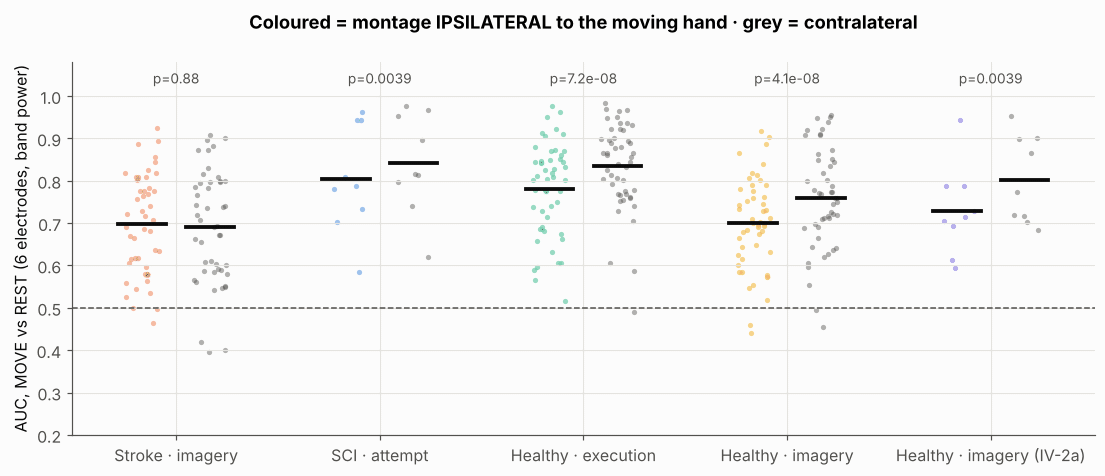

,dataset,hemisphere,n,mean_auc,ci_low,ci_high
0,Stroke · imagery,ipsi,47,0.697,0.663,0.730
1,Stroke · imagery,contra,47,0.690,0.652,0.726
2,SCI · attempt,ipsi,9,0.805,0.730,0.881
3,SCI · attempt,contra,9,0.842,0.769,0.912
4,Healthy · execution,ipsi,49,0.781,0.749,0.810
5,Healthy · execution,contra,49,0.835,0.806,0.862
6,Healthy · imagery,ipsi,49,0.701,0.672,0.730
7,Healthy · imagery,contra,49,0.759,0.727,0.792
8,Healthy · imagery (IV-2a),ipsi,9,0.730,0.670,0.795
9,Healthy · imagery (IV-2a),contra,9,0.802,0.738,0.866


In [3]:
fig, ax = plt.subplots(figsize=(12, 4.4))
rng = np.random.default_rng(0); rows = []
for i, k in enumerate(ORDER):
    for j, hemi in enumerate(["ipsi", "contra"]):
        t = tab("6ch_bandpower", hemi)[k].dropna(); x = i * 3 + j
        ax.scatter(x + rng.uniform(-.25, .25, len(t)), t, s=12, alpha=.45, lw=0, color=COL[k] if hemi == "ipsi" else V.INK2)
        ax.plot([x - .35, x + .35], [t.mean()] * 2, color=V.INK, lw=2.5)
        lo, hi = ci(t); rows.append(dict(dataset=LABEL[k], hemisphere=hemi, n=len(t), mean_auc=t.mean(), ci_low=lo, ci_high=hi))
    a, b = tab("6ch_bandpower", "ipsi")[k].dropna(), tab("6ch_bandpower", "contra")[k].dropna()
    p = stats.wilcoxon(a, b.loc[a.index]).pvalue
    ax.text(i * 3 + .5, 1.03, f"p={p:.2g}", ha="center", fontsize=9, color=V.INK2)
ax.axhline(.5, color=V.INK2, ls="--", lw=1)
ax.set_xticks([i * 3 + .5 for i in range(len(ORDER))]); ax.set_xticklabels([LABEL[k] for k in ORDER])
ax.set_ylabel("AUC, MOVE vs REST (6 electrodes, band power)"); ax.set_ylim(.2, 1.08)
ax.set_title("Coloured = montage IPSILATERAL to the moving hand · grey = contralateral", pad=22); plt.show()
pd.DataFrame(rows).round(3)

**Result.** In every dataset, the montage **ipsilateral** to the moving hand decodes MOVE vs REST well above chance (mean AUC 0.70–0.81).

- **Healthy and SCI:** the contralateral montage is better (p < 0.005 in 4 datasets), as expected from normal motor organisation.
- **Stroke:** the two hemispheres are **equivalent** (0.697 vs 0.690, p = 0.88). In these patients the healthy hemisphere carries as much intent information as the classical (lesioned) motor cortex. That is the situation a contralesional device relies on.

## 5 · Attempt vs imagery vs execution

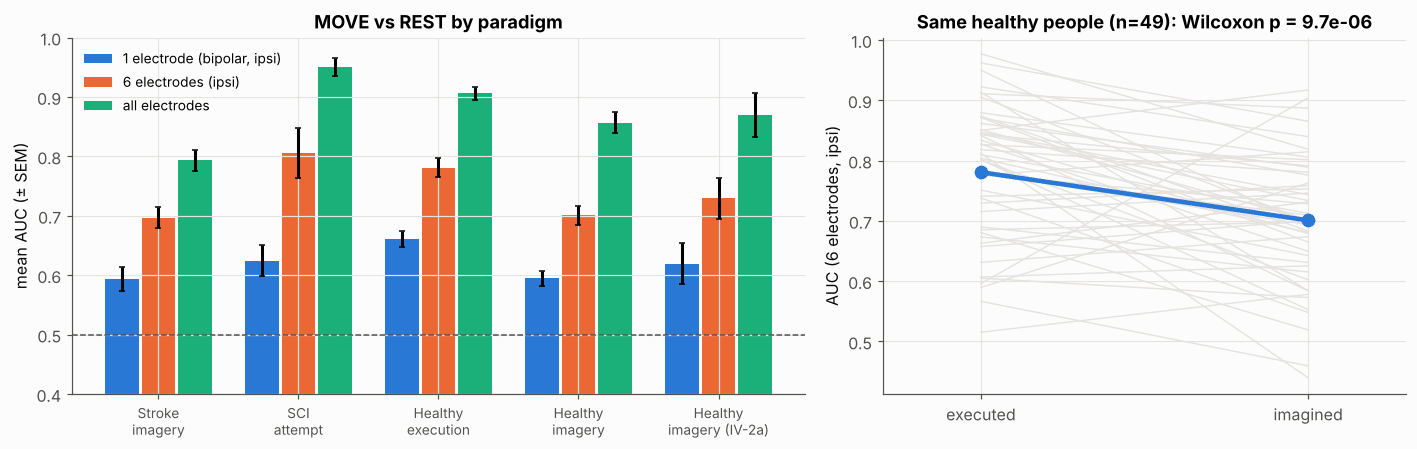

pipeline,1ch_bipolar,6ch_bandpower,all_tangent
dataset,,,
liu2024,0.594,0.697,0.793
bnci2019,0.625,0.805,0.950
physionet_exec,0.661,0.781,0.906
physionet_imag,0.595,0.701,0.857
bnci2014,0.619,0.730,0.870


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.4, 1]))
rows = []
for i, k in enumerate(ORDER):
    for j, (pipe, hemi) in enumerate([("1ch_bipolar", "ipsi"), ("6ch_bandpower", "ipsi"), ("all_tangent", "both")]):
        t = tab(pipe, hemi)[k].dropna(); rows.append(dict(dataset=k, pipeline=pipe, auc=t.mean(), se=t.std() / np.sqrt(len(t))))
d = pd.DataFrame(rows)
w = .26
for j, (pipe, lab) in enumerate([("1ch_bipolar", "1 electrode (bipolar, ipsi)"), ("6ch_bandpower", "6 electrodes (ipsi)"), ("all_tangent", "all electrodes")]):
    dd = d[d.pipeline == pipe].set_index("dataset").reindex(ORDER)
    ax[0].bar(np.arange(len(ORDER)) + (j - 1) * w, dd.auc, w * .92, yerr=dd.se, capsize=2, color=V.SERIES[j], label=lab)
ax[0].axhline(.5, color=V.INK2, ls="--", lw=1); ax[0].set_ylim(.4, 1.0); ax[0].set_xticks(range(len(ORDER))); ax[0].set_xticklabels([LABEL[k].replace(" · ", "\n") for k in ORDER], fontsize=9)
ax[0].set_ylabel("mean AUC (± SEM)"); ax[0].legend(fontsize=9, loc="upper left"); ax[0].set_title("MOVE vs REST by paradigm")
pe, pi = tab("6ch_bandpower", "ipsi")["physionet_exec"].dropna(), tab("6ch_bandpower", "ipsi")["physionet_imag"].dropna()
common = pe.index.intersection(pi.index)
ax[1].plot([0, 1], [pe[common], pi[common]], color=V.GRID, lw=1); ax[1].plot([0, 1], [pe[common].mean(), pi[common].mean()], color=V.SERIES[0], lw=3, marker="o", ms=8)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["executed", "imagined"]); ax[1].set_xlim(-.3, 1.3); ax[1].set_ylabel("AUC (6 electrodes, ipsi)")
ax[1].set_title(f"Same healthy people (n={len(common)}): Wilcoxon p = {stats.wilcoxon(pe[common], pi[common]).pvalue:.2g}")
plt.tight_layout(); plt.show()
d.pivot(index="dataset", columns="pipeline", values="auc").reindex(ORDER).round(3)

**Result.** Movement that is **executed or attempted** is easier to detect than imagery.

- **Same 49 healthy people:** 0.78 (executed) vs 0.70 (imagined), p < 10⁻⁵.
- **SCI attempt:** 0.81 with 6 ipsilateral electrodes and 0.95 with all electrodes, the highest of all datasets. The paradigm matches Kandu's: patients *attempt* to move a paralysed hand.

The stroke imagery figures (Notebook 02) are therefore a **lower bound** for an attempt-based device. More electrodes help everywhere (1 → 6 → all).

## 6 · Confound baselines: eyes and forehead vs motor cortex
If the eye channels decode MOVE vs REST as well as the motor channels, the decoder may be reading **gaze, blinks or visual stimulation** rather than motor intent. Two control tasks remove most of the confound by design. **Left vs right hand** uses the same screen and the same timing. **BNCI 2019 vs true rest** compares attempt with 70-s rest runs.

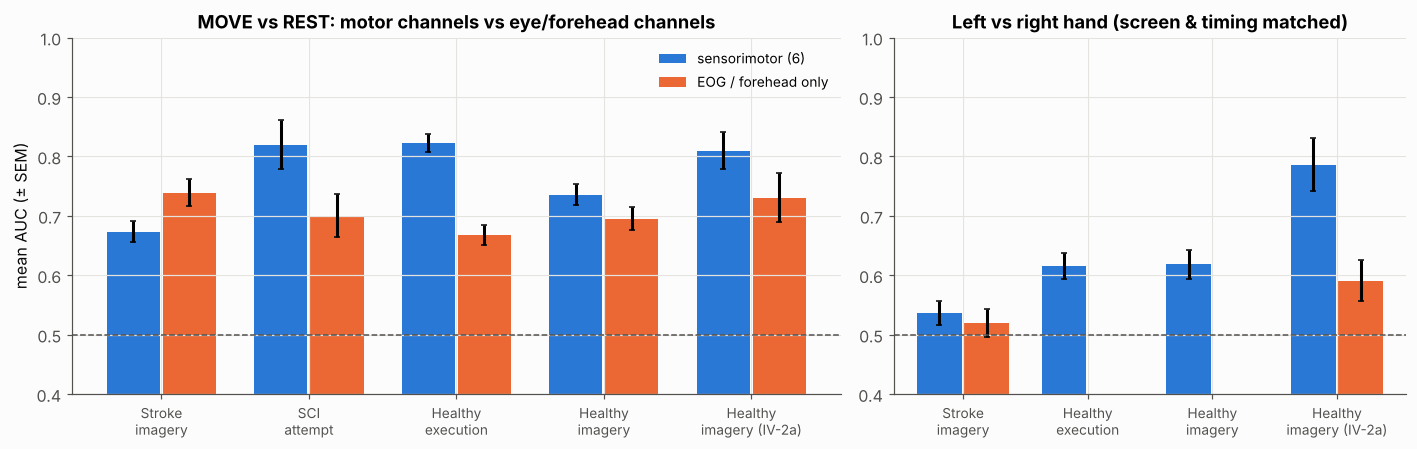

BNCI 2019 (attempt), mean AUC  | vs pre-cue fixation | vs 70-s true rest
  6ch_bandpower              | 0.805               | 0.832
  all_tangent                | 0.950               | 0.993
  eog_only                   | 0.700               | 0.773


baseline,EOG / forehead only,sensorimotor (6)
dataset,,
liu2024,0.739,0.673
bnci2019,0.700,0.819
physionet_exec,0.668,0.823
physionet_imag,0.695,0.736
bnci2014,0.730,0.809


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[1.5, 1]))
rows = []
for i, k in enumerate(ORDER):
    base = "eog_only" if k not in ("physionet_exec", "physionet_imag") else "frontal_pole"
    for j, (pipe, hemi, lab) in enumerate([("sensorimotor6_bandpower", "both", "sensorimotor (6)"), (base, "none", "EOG / forehead only")]):
        t = tab(pipe, hemi)[k].dropna(); rows.append(dict(dataset=k, baseline=lab, auc=t.mean(), se=t.std() / np.sqrt(len(t)), n=len(t)))
d = pd.DataFrame(rows)
for j, lab in enumerate(["sensorimotor (6)", "EOG / forehead only"]):
    dd = d[d.baseline == lab].set_index("dataset").reindex(ORDER)
    ax[0].bar(np.arange(len(ORDER)) + (j - .5) * .38, dd.auc, .36, yerr=dd.se, capsize=2, color=[V.SERIES[0], V.SERIES[1]][j], label=lab)
ax[0].axhline(.5, color=V.INK2, ls="--", lw=1); ax[0].set_ylim(.4, 1.0); ax[0].set_xticks(range(len(ORDER))); ax[0].set_xticklabels([LABEL[k].replace(" · ", "\n") for k in ORDER], fontsize=9)
ax[0].legend(fontsize=9); ax[0].set_ylabel("mean AUC (± SEM)"); ax[0].set_title("MOVE vs REST: motor channels vs eye/forehead channels")
lr = auc[auc.role == "left_vs_right"].pivot_table(index=["dataset_key", "subject"], columns="pipeline", values="auc").reset_index()
xs = []
for i, k in enumerate([k for k in ORDER if k in lr.dataset_key.unique()]):
    t = lr[lr.dataset_key == k]
    for j, (pipe, colr) in enumerate([("lr_sensorimotor6", V.SERIES[0]), ("lr_eog_only", V.SERIES[1])]):
        if pipe in t and t[pipe].notna().any():
            ax[1].bar(i + (j - .5) * .38, t[pipe].mean(), .36, yerr=t[pipe].std() / np.sqrt(t[pipe].notna().sum()), capsize=2, color=colr)
    xs.append(LABEL[k].replace(" · ", "\n"))
ax[1].axhline(.5, color=V.INK2, ls="--", lw=1); ax[1].set_ylim(.4, 1.0); ax[1].set_xticks(range(len(xs))); ax[1].set_xticklabels(xs, fontsize=9)
ax[1].set_title("Left vs right hand (screen & timing matched)"); plt.tight_layout(); plt.show()
tr = auc[(auc.dataset_key == "bnci2019") & (auc.role == "vs_true_rest")].pivot_table(index="subject", columns="pipeline", values="auc")
pre = per_sub[(per_sub.dataset_key == "bnci2019")].pivot_table(index="subject", columns=["pipeline", "hemisphere"], values="auc")
print("BNCI 2019 (attempt), mean AUC  | vs pre-cue fixation | vs 70-s true rest")
for pipe, hemi in [("6ch_bandpower", "ipsi"), ("all_tangent", "both"), ("eog_only", "none")]:
    print(f"  {pipe:15s}            | {pre[(pipe, hemi)].mean():.3f}               | {tr[pipe].mean():.3f}")
d.pivot(index="dataset", columns="baseline", values="auc").reindex(ORDER).round(3)

**Result.**

- **Eye / forehead channels alone** reach AUC 0.67–0.74 for MOVE vs REST in **every** dataset, including the IV-2a benchmark. Any decoding claim needs this baseline next to it.
- **Stroke is the only dataset where they beat the motor channels.** Its imagery phase shows a moving video, while rest shows a static picture.
- **SCI attempt** (same fixation cross in rest and move): motor 0.82 vs EOG 0.70. Against the 70-s true rest runs, the 6-electrode montage rises to 0.83 and EOG to 0.77. A long rest block differs from a pre-cue window in more than motor state (alertness, gaze), so the calibration rest condition should match the use condition.
- **Left vs right hand** (screen and timing matched): sensorimotor channels carry the information (healthy 0.62, IV-2a 0.79); the eye channels drop. Stroke left-vs-right stays near chance (0.54).

PhysioNet has no EOG channels, so its eye baseline uses Fp1, Fp2, AF7 and AF8, and its left-vs-right eye baseline is not available.

## 7 · Lateralisation of the ERD: a normative reference for the stroke result
Notebook 02 found that in the stroke data the ERD is stronger over the hemisphere *ipsilateral* to whichever hand is imagined, which is atypical. Healthy datasets processed with the **same code** show what a typical laterality looks like.
`laterality = ERD(contra) − ERD(ipsi)` in dB: **negative = contralateral dominance** (typical), positive = ipsilateral dominance.

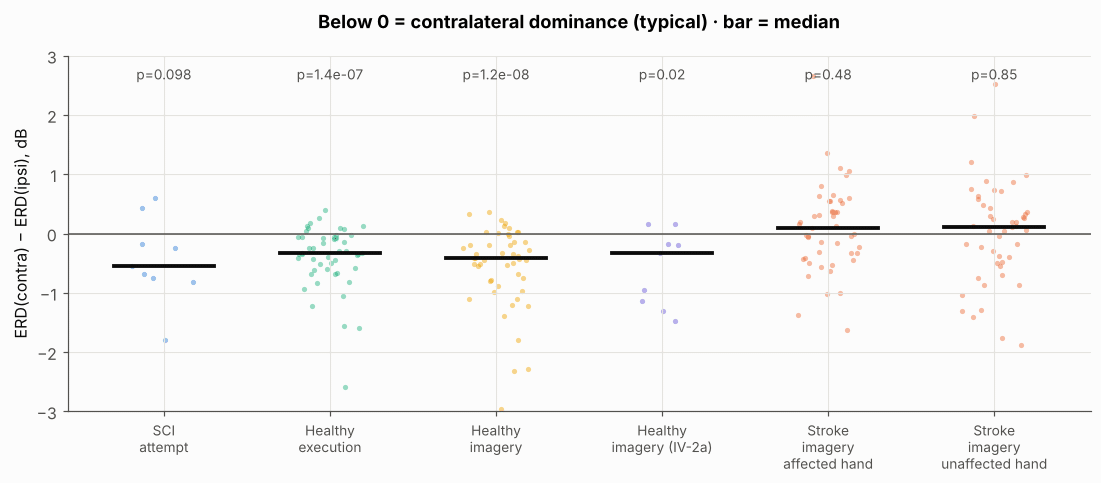

,group,n,median_laterality_dB,pct_contralateral,p
0,SCI · attempt,9,-0.551,77.778,0.098
1,Healthy · execution,49,-0.332,81.633,0.000
2,Healthy · imagery,49,-0.413,79.592,0.000
3,Healthy · imagery (IV-2a),9,-0.332,77.778,0.020
4,Stroke · imagery (affected hand),47,0.094,48.936,0.479
5,Stroke · imagery (unaffected hand),47,0.102,42.553,0.854


In [6]:
e = erd.copy()
e = e[~e.role.isin(["unaffected"]) | (e.dataset_key == "liu2024")]
w = e.pivot_table(index=["dataset_key", "subject", "role"], columns="hemisphere", values="erd_db").reset_index()
w["laterality"] = w["contra"] - w["ipsi"]
lat = w.groupby(["dataset_key", "subject"]).laterality.mean().reset_index() if False else w
fig, ax = plt.subplots(figsize=(12, 4.2)); rows = []
groups = [(k, None) for k in ORDER if k != "liu2024"] + [("liu2024", "affected"), ("liu2024", "unaffected")]
for i, (k, role) in enumerate(groups):
    t = w[(w.dataset_key == k) & ((w.role == role) if role else True)]
    t = t.groupby("subject").laterality.mean()
    ax.scatter(i + rng.uniform(-.2, .2, len(t)), t, s=12, alpha=.45, lw=0, color=COL[k]); ax.plot([i - .3, i + .3], [t.median()] * 2, color=V.INK, lw=2.5)
    p = stats.wilcoxon(t).pvalue; ax.text(i, 2.6, f"p={p:.2g}", ha="center", fontsize=9, color=V.INK2)
    rows.append(dict(group=LABEL[k] + (f" ({role} hand)" if role else ""), n=len(t), median_laterality_dB=t.median(), pct_contralateral=(t < 0).mean() * 100, p=p))
ax.axhline(0, color=V.INK2, lw=1); ax.set_ylim(-3, 3)
ax.set_xticks(range(len(groups))); ax.set_xticklabels([LABEL[k].replace(" · ", "\n") + (f"\n{r} hand" if r else "") for k, r in groups], fontsize=9)
ax.set_ylabel("ERD(contra) − ERD(ipsi), dB"); ax.set_title("Below 0 = contralateral dominance (typical) · bar = median", pad=18); plt.show()
pd.DataFrame(rows).round(3)

**Result.** With identical code:

- **Healthy and SCI:** contralateral dominance in **78–82%** of subjects (PhysioNet p < 10⁻⁷, IV-2a p = 0.02; SCI p = 0.10 with n = 9). This is the textbook pattern, and it shows the processing is correct.
- **Stroke:** no lateralisation for either hand. 49% (affected) and 43% (unaffected) contralateral; medians near 0 dB, p ≥ 0.48.

This sharpens the Notebook 02 caveat. The atypical stroke pattern is **not a processing artefact**. It is also unlike a simple left/right label swap: a swap would give ~80% *ipsilateral* dominance, not ~50%. The most likely reading is a genuine **loss of the normal lateralisation** (bilateral or ipsilateral recruitment) in acute stroke, which is consistent with the literature on post-stroke reorganisation.

## 8 · Electrode count and reference, across datasets

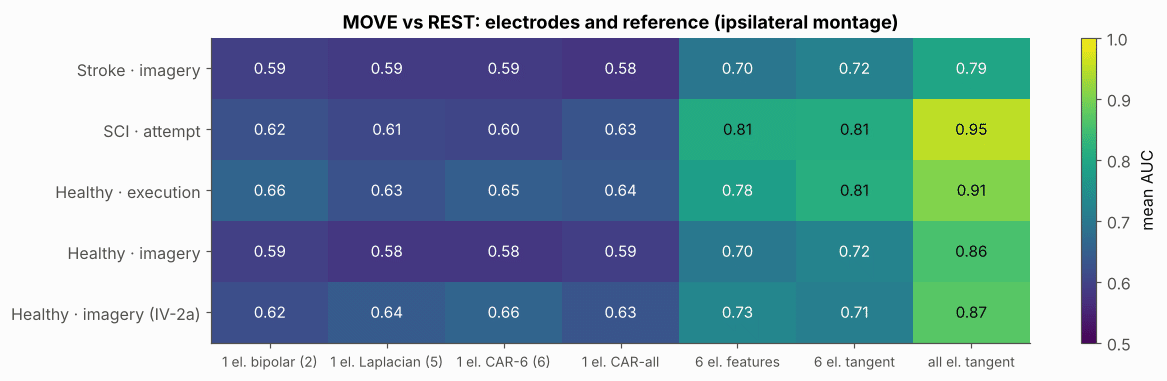

,dataset,friedman_p_1ch_references,p_6ch_vs_best_1ch
0,Stroke · imagery,0.8870,0.8906
1,SCI · attempt,0.9536,0.0039
2,Healthy · execution,0.0691,0.0000
3,Healthy · imagery,0.7209,0.0002
4,Healthy · imagery (IV-2a),0.4346,0.0078


In [7]:
pipes = [("1ch_bipolar", "ipsi", "1 el. bipolar (2)"), ("1ch_laplacian", "ipsi", "1 el. Laplacian (5)"), ("1ch_car6", "ipsi", "1 el. CAR-6 (6)"),
         ("1ch_car_all", "ipsi", "1 el. CAR-all"), ("6ch_bandpower", "ipsi", "6 el. features"), ("6ch_tangent", "ipsi", "6 el. tangent"), ("all_tangent", "both", "all el. tangent")]
M = pd.DataFrame({lab: [tab(p, h)[k].mean() for k in ORDER] for p, h, lab in pipes}, index=[LABEL[k] for k in ORDER])
fig, ax = plt.subplots(figsize=(12, 3.6))
im = ax.imshow(M.values, cmap="viridis", vmin=.5, vmax=1.0, aspect="auto")
for (i, j), v in np.ndenumerate(M.values): ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v < .8 else V.INK, fontsize=10)
ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, fontsize=9); ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index); ax.grid(False)
plt.colorbar(im, ax=ax, label="mean AUC"); ax.set_title("MOVE vs REST: electrodes and reference (ipsilateral montage)"); plt.show()
fr = []
for k in ORDER:
    sub = per_sub[(per_sub.dataset_key == k) & (per_sub.pipeline.str.startswith("1ch_")) & (per_sub.hemisphere == "ipsi")].pivot(index="subject", columns="pipeline", values="auc").dropna()
    fr.append(dict(dataset=LABEL[k], friedman_p_1ch_references=stats.friedmanchisquare(*[sub[c] for c in sub]).pvalue,
                   p_6ch_vs_best_1ch=stats.wilcoxon(tab("6ch_bandpower", "ipsi")[k].dropna(), sub.max(axis=1).reindex(tab("6ch_bandpower", "ipsi")[k].dropna().index)).pvalue))
pd.DataFrame(fr).round(4)

**Result.**

- **One electrode:** the choice among bipolar, Laplacian, CAR-6 and whole-head CAR makes no significant difference in any dataset (Friedman p = 0.07–0.95). A 2-electrode bipolar derivation is as good as the 6-electrode CAR design.
- **6 electrodes as features** beat the *best* of the four single-electrode variants in 4 of 5 datasets (p ≤ 0.008). Stroke is the exception (p = 0.89), where per-patient selection of the best reference already captures most of the gain.
- **All channels** add a further 0.07–0.15 AUC, partly from non-motor (eye, visual) information.

## 9 · Slow potentials (MRCP) vs oscillations
Movement-related cortical potentials are slow negative shifts (0.3–3 Hz) over the motor strip that start before and at movement onset. They are the basis of the Graz SCI work (Ofner et al. 2019), and they are complementary to the μ/β ERD.

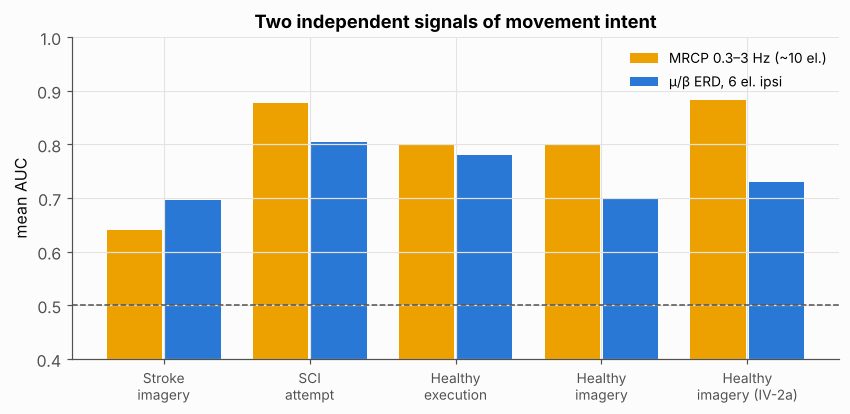

,dataset,n,mrcp_auc,erd_6ch_auc,p
0,Stroke · imagery,47,0.640,0.697,0.023
1,SCI · attempt,9,0.877,0.805,0.203
2,Healthy · execution,49,0.799,0.781,0.401
3,Healthy · imagery,49,0.800,0.701,0.000
4,Healthy · imagery (IV-2a),9,0.882,0.730,0.008


In [8]:
rows = []
for k in ORDER:
    m = tab("mrcp_0.3-3Hz", "both")[k].dropna(); o = tab("6ch_bandpower", "ipsi")[k].dropna()
    common = m.index.intersection(o.index)
    rows.append(dict(dataset=LABEL[k], n=len(common), mrcp_auc=m[common].mean(), erd_6ch_auc=o[common].mean(), p=stats.wilcoxon(m[common], o[common]).pvalue))
t = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(t)); ax.bar(x - .2, t.mrcp_auc, .38, color=V.SERIES[3], label="MRCP 0.3–3 Hz (~10 el.)"); ax.bar(x + .2, t.erd_6ch_auc, .38, color=V.SERIES[0], label="μ/β ERD, 6 el. ipsi")
ax.axhline(.5, color=V.INK2, ls="--", lw=1); ax.set_ylim(.4, 1); ax.set_xticks(x); ax.set_xticklabels([l.replace(" · ", "\n") for l in t.dataset], fontsize=9); ax.legend(fontsize=9); ax.set_ylabel("mean AUC")
ax.set_title("Two independent signals of movement intent"); plt.show()
t.round(3)

**Result.**

- **Slow potentials decode MOVE vs REST well:** 0.88 for SCI attempt, 0.80 for healthy execution. In the cued imagery datasets they even beat the ERD (healthy imagery 0.80 vs 0.70; IV-2a 0.88 vs 0.73).
- **Caveat:** these windows are *cue-locked*. A visual cue produces its own slow evoked potentials (P300 and similar), so part of this "MRCP" performance is sensory, not motor. In the stroke data, where rest and move both contain visual stimuli, MRCP is the weaker feature (0.64 vs 0.70).
- **For a device:** MRCPs are a promising **second, independent feature** (Ofner et al. 2019 used them in SCI). They should be validated with *self-paced* movements, where no cue is present.

## 10 · Summary
| Question | Stroke (imagery) | SCI (attempt) | Healthy (execution) | Healthy (imagery) | IV-2a (imagery) |
|---|---|---|---|---|---|
| 6-el. ipsi montage, AUC | 0.70 | 0.81 | 0.78 | 0.70 | 0.73 |
| all electrodes, AUC | 0.79 | 0.95 | 0.91 | 0.86 | 0.87 |
| eye / forehead only, AUC | 0.74 | 0.70 | 0.67 | 0.70 | 0.73 |
| contralateral dominance | 49% | 78% | 82% | 80% | 78% |
| 1-electrode reference matters? | no | no | no | no | no |

**Implications for a Kandu-type device**
1. The contralesional premise is supported: the hemisphere ipsilateral to the hand carries decodable intent, and after stroke it is as informative as the lesioned side.
2. Expect **better** performance with attempted movement than the stroke-imagery numbers suggest (SCI attempt: 0.81 with 6 electrodes).
3. Single-electrode reference design is not where gains are; **multivariate use of the existing electrodes** is.
4. **Calibration protocol:** keep the visual display identical between rest and attempt, and report an EOG baseline.
5. MRCPs are a candidate second feature, to be validated self-paced.